# 葡萄实例分割训练 - 使用SAM自动标注
## 步骤1: 用SAM从边界框生成精确分割标注
## 步骤2: 训练YOLOv8-seg实例分割模型
## 自动保存到 models/grape_segment_model.pt

## 1. 安装依赖

In [1]:
!pip install ultralytics opencv-python matplotlib pillow numpy pyyaml segment-anything torch torchvision -q
print('✓ 依赖安装完成')

✓ 依赖安装完成


## 2. 导入库

In [2]:
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import yaml
import shutil
import torch
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

from segment_anything import sam_model_registry, SamPredictor
from ultralytics import YOLO

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print('✓ 库导入完成')
print(f'PyTorch版本: {torch.__version__}')
print(f'CUDA可用: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

✓ 库导入完成
PyTorch版本: 1.13.1
CUDA可用: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 3. 配置参数

In [ ]:
# 获取项目根目录
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'train' else Path.cwd()
MODELS_DIR = PROJECT_ROOT / 'models'
TRAIN_DIR = PROJECT_ROOT / 'train'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 查找SAM模型
SAM_MODEL_TYPE = 'vit_b'
possible_sam_paths = [
    TRAIN_DIR / 'sam_vit_b_01ec64.pth',
    MODELS_DIR / 'sam_vit_b_01ec64.pth',
    MODELS_DIR / 'sam_vit_b.pth',
]

sam_checkpoint_path = None
for path in possible_sam_paths:
    if path.exists():
        sam_checkpoint_path = path
        print(f'✓ 找到SAM模型: {path}')
        print(f'  大小: {path.stat().st_size / 1024**2:.1f} MB')
        break

if sam_checkpoint_path is None:
    raise FileNotFoundError('未找到SAM模型文件！请先下载 sam_vit_b_01ec64.pth')

CONFIG = {
    # 路径配置
    'data_root': PROJECT_ROOT / 'Grape Detection Segment' / 'MyData',
    'output_root': PROJECT_ROOT / 'Grape Detection Segment' / 'yolo_seg_dataset',
    'project_dir': PROJECT_ROOT / 'train' / 'runs' / 'grape_segment',
    'models_dir': MODELS_DIR,
    'sam_checkpoint': sam_checkpoint_path,
    'sam_model_type': SAM_MODEL_TYPE,
    
    # 数据集配置
    'varieties': ['Chardonnay', 'PinotGris', 'PinotNoir'],
    'class_to_id': {'Chardonnay': 0, 'PinotGris': 1, 'PinotNoir': 2},
    'train_ratio': 0.7,
    'val_ratio': 0.15,
    'test_ratio': 0.15,
    'random_seed': 42,
    
    # YOLO训练配置
    'model_size': 'yolov8m-seg.pt',
    'epochs': 150,
    'batch_size': 8,
    'img_size': 640,
    'patience': 20,  # ✅ 从30改为20，更早停止
    'optimizer': 'AdamW',
    'lr0': 0.001,
    'lrf': 0.01,
    'weight_decay': 0.0005,  # ✅ 添加权重衰减，防止过拟合
    
    # 数据增强
    'hsv_h': 0.015,
    'hsv_s': 0.7,
    'hsv_v': 0.4,
    'degrees': 10.0,
    'translate': 0.1,
    'scale': 0.5,
    'flipud': 0.0,
    'fliplr': 0.5,
    'mosaic': 1.0,
    'mixup': 0.1,
    'copy_paste': 0.3,
    
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'workers': 8,
}

print('\n配置参数:')
print(f'  数据根目录: {CONFIG["data_root"]}')
print(f'  输出目录: {CONFIG["output_root"]}')
print(f'  SAM模型: {CONFIG["sam_model_type"]}')
print(f'  YOLO模型: {CONFIG["model_size"]}')
print(f'  设备: {CONFIG["device"]}')
print(f'  早停patience: {CONFIG["patience"]}轮 (监控验证集mAP)')
print(f'  权重衰减: {CONFIG["weight_decay"]} (L2正则化)')
print(f'\n最终模型将保存到: {MODELS_DIR / "grape_segment_model.pt"}')

## 4. 加载SAM模型

In [4]:
print('加载SAM模型...')
print(f'模型路径: {CONFIG["sam_checkpoint"]}')

try:
    # 方法1: 直接加载（推荐）
    sam = sam_model_registry[CONFIG['sam_model_type']](checkpoint=str(CONFIG['sam_checkpoint']))
    print('✓ 使用方法1加载成功')
except Exception as e1:
    print(f'方法1失败: {e1}')
    print('尝试方法2...')
    
    try:
        # 方法2: 手动加载权重
        state_dict = torch.load(CONFIG['sam_checkpoint'], map_location='cpu')
        sam = sam_model_registry[CONFIG['sam_model_type']](checkpoint=None)
        sam.load_state_dict(state_dict)
        print('✓ 使用方法2加载成功')
    except Exception as e2:
        print(f'方法2失败: {e2}')
        raise RuntimeError(f'SAM模型加载失败！请检查模型文件是否损坏。\n错误1: {e1}\n错误2: {e2}')

# 移动到设备
sam.to(device=CONFIG['device'])
sam_predictor = SamPredictor(sam)

print(f'✓ SAM模型已加载到 {CONFIG["device"]}')
print(f'✓ SamPredictor已就绪')

加载SAM模型...
模型路径: D:\WorkSpace2\plants-intelligent-system\train\sam_vit_b_01ec64.pth
✓ 使用方法1加载成功
✓ SAM模型已加载到 cuda
✓ SamPredictor已就绪


## 5. 定义辅助函数

In [5]:
def bbox_to_sam_input(bbox, img_width, img_height):
    """将YOLO归一化边界框转换为SAM输入格式"""
    x_center, y_center, w, h = bbox
    x1 = int((x_center - w/2) * img_width)
    y1 = int((y_center - h/2) * img_height)
    x2 = int((x_center + w/2) * img_width)
    y2 = int((y_center + h/2) * img_height)
    return np.array([x1, y1, x2, y2])

def mask_to_polygon(mask):
    """将二值掩码转换为多边形坐标"""
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if len(contours) == 0:
        return None
    
    # 取最大的轮廓
    contour = max(contours, key=cv2.contourArea)
    
    # 简化轮廓
    epsilon = 0.002 * cv2.arcLength(contour, True)
    approx = cv2.approxPolyDP(contour, epsilon, True)
    polygon = approx.reshape(-1, 2)
    
    return polygon

print('✓ 辅助函数已定义')

✓ 辅助函数已定义


## 6. 使用SAM生成分割标注

In [ ]:
def generate_segmentation_labels(data_root, sam_predictor, varieties, class_to_id):
    """为所有图片生成SAM分割标注"""
    all_samples = []
    
    for variety in varieties:
        print(f'\n处理品种: {variety}')
        
        images_dir = data_root / variety / 'images'
        labels_dir = data_root / variety / 'labels'
        
        if not images_dir.exists():
            print(f'  ⚠ 图片目录不存在: {images_dir}')
            continue
        
        image_files = list(images_dir.glob('*.jpg')) + list(images_dir.glob('*.JPG'))
        class_id = class_to_id[variety]
        
        print(f'  找到 {len(image_files)} 张图片')
        
        for img_file in tqdm(image_files, desc='标注', leave=False, dynamic_ncols=True):
            label_file = labels_dir / (img_file.stem + '.txt')
            
            if not label_file.exists():
                continue
            
            # 读取图片
            image = cv2.imread(str(img_file))
            if image is None:
                print(f'  ⚠ 无法读取: {img_file.name}')
                continue
                
            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            h, w = image.shape[:2]
            
            # 设置图片到SAM
            sam_predictor.set_image(image_rgb)
            
            # 读取边界框标注
            bboxes = []
            with open(label_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        bbox = list(map(float, parts[1:5]))
                        bboxes.append(bbox)
            
            if len(bboxes) == 0:
                continue
            
            # 为每个边界框生成分割掩码
            seg_annotations = []
            
            for bbox in bboxes:
                box_xyxy = bbox_to_sam_input(bbox, w, h)
                
                # 使用SAM生成掩码
                masks, scores, _ = sam_predictor.predict(
                    box=box_xyxy,
                    multimask_output=False
                )
                
                mask = masks[0]
                polygon = mask_to_polygon(mask)
                
                if polygon is not None and len(polygon) >= 3:
                    # 归一化坐标
                    polygon_normalized = polygon.copy().astype(float)
                    polygon_normalized[:, 0] /= w
                    polygon_normalized[:, 1] /= h
                    
                    seg_annotations.append({
                        'class_id': class_id,
                        'polygon': polygon_normalized
                    })
            
            if len(seg_annotations) > 0:
                all_samples.append({
                    'image': img_file,
                    'annotations': seg_annotations,
                    'variety': variety
                })
    
    return all_samples

# 生成分割标注
print('='*70)
print('步骤1: 使用SAM生成分割标注')
print('='*70)

all_samples = generate_segmentation_labels(
    CONFIG['data_root'],
    sam_predictor,
    CONFIG['varieties'],
    CONFIG['class_to_id']
)

print(f'\n✓ 共生成 {len(all_samples)} 个样本的分割标注')

## 7. 划分数据集并保存YOLO格式

In [ ]:
import random
random.seed(CONFIG['random_seed'])

# 打乱并划分数据集
random.shuffle(all_samples)
n_total = len(all_samples)
n_train = int(n_total * CONFIG['train_ratio'])
n_val = int(n_total * CONFIG['val_ratio'])

train_samples = all_samples[:n_train]
val_samples = all_samples[n_train:n_train + n_val]
test_samples = all_samples[n_train + n_val:]

print(f'数据集划分:')
print(f'  训练集: {len(train_samples)} 样本')
print(f'  验证集: {len(val_samples)} 样本')
print(f'  测试集: {len(test_samples)} 样本')

# 创建YOLO数据集目录
output_root = CONFIG['output_root']
for split in ['train', 'valid', 'test']:
    (output_root / split / 'images').mkdir(parents=True, exist_ok=True)
    (output_root / split / 'labels').mkdir(parents=True, exist_ok=True)

def save_yolo_seg_format(samples, split, output_root):
    """保存为YOLO分割格式"""
    for idx, sample in enumerate(tqdm(samples, desc='保存', leave=False, dynamic_ncols=True)):
        img_name = f"{sample['variety']}_{idx:04d}{sample['image'].suffix}"
        img_dst = output_root / split / 'images' / img_name
        shutil.copy(sample['image'], img_dst)
        
        label_name = img_name.replace(sample['image'].suffix, '.txt')
        label_dst = output_root / split / 'labels' / label_name
        
        with open(label_dst, 'w') as f:
            for ann in sample['annotations']:
                polygon = ann['polygon']
                class_id = ann['class_id']
                coords = ' '.join([f"{x:.6f} {y:.6f}" for x, y in polygon])
                f.write(f"{class_id} {coords}\n")

save_yolo_seg_format(train_samples, 'train', output_root)
save_yolo_seg_format(val_samples, 'valid', output_root)
save_yolo_seg_format(test_samples, 'test', output_root)

print('\n✓ YOLO分割格式数据集已保存')

## 8. 创建data.yaml配置

In [8]:
data_yaml = {
    'path': str(output_root.absolute()),
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': len(CONFIG['varieties']),
    'names': CONFIG['varieties']
}

data_yaml_path = output_root / 'data.yaml'
with open(data_yaml_path, 'w', encoding='utf-8') as f:
    yaml.dump(data_yaml, f, allow_unicode=True, sort_keys=False)

print('data.yaml:')
print(yaml.dump(data_yaml, allow_unicode=True, sort_keys=False))

data.yaml:
path: D:\WorkSpace2\plants-intelligent-system\Grape Detection Segment\yolo_seg_dataset
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- Chardonnay
- PinotGris
- PinotNoir


## 9. 可视化SAM生成的分割标注

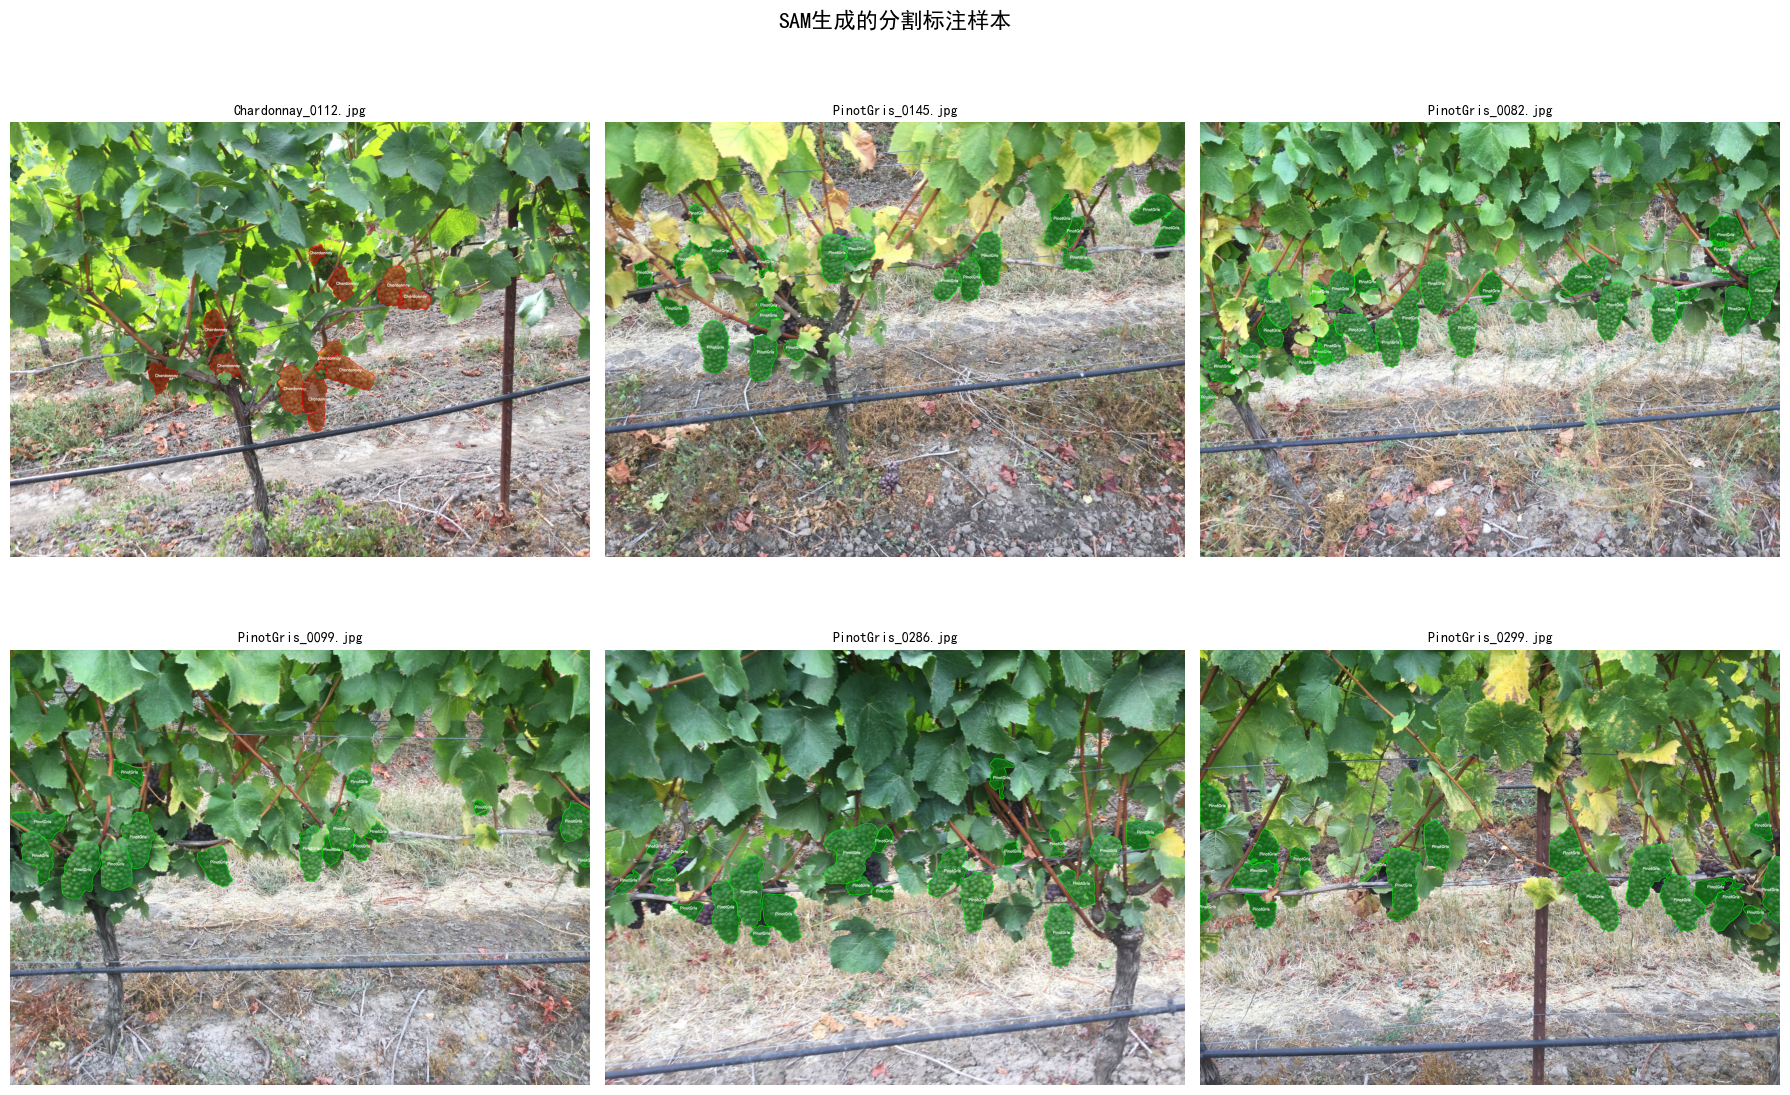

In [9]:
def visualize_seg_samples(images_dir, labels_dir, class_names, num_samples=6):
    image_files = list(images_dir.glob('*.jpg')) + list(images_dir.glob('*.JPG'))
    if len(image_files) == 0:
        print('没有图像文件')
        return
        
    sample_files = np.random.choice(image_files, min(num_samples, len(image_files)), replace=False)
    
    fig = plt.figure(figsize=(18, 12))
    colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255)]
    
    for idx, img_file in enumerate(sample_files):
        img = cv2.imread(str(img_file))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        
        label_file = labels_dir / (img_file.stem + '.txt')
        
        if label_file.exists():
            with open(label_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) < 4:
                        continue
                    
                    class_id = int(parts[0])
                    coords = list(map(float, parts[1:]))
                    
                    points = []
                    for i in range(0, len(coords), 2):
                        x = int(coords[i] * w)
                        y = int(coords[i + 1] * h)
                        points.append([x, y])
                    
                    if len(points) > 0:
                        points = np.array(points, dtype=np.int32)
                        color = colors[class_id % len(colors)]
                        
                        cv2.polylines(img, [points], True, color, 2)
                        overlay = img.copy()
                        cv2.fillPoly(overlay, [points], color)
                        img = cv2.addWeighted(img, 0.7, overlay, 0.3, 0)
                        
                        cx = int(np.mean(points[:, 0]))
                        cy = int(np.mean(points[:, 1]))
                        cv2.putText(img, class_names[class_id], (cx - 40, cy),
                                  cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        
        ax = fig.add_subplot(2, 3, idx + 1)
        ax.imshow(img)
        ax.set_title(img_file.name, fontsize=10)
        ax.axis('off')
    
    plt.suptitle('SAM生成的分割标注样本', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

visualize_seg_samples(
    output_root / 'train' / 'images',
    output_root / 'train' / 'labels',
    CONFIG['varieties'],
    num_samples=6
)

## 10. 训练YOLOv8-seg模型

In [ ]:
print('='*70)
print('步骤2: 训练YOLOv8-seg实例分割模型')
print('='*70)

model = YOLO(CONFIG['model_size'])
print(f'✓ 已加载 {CONFIG["model_size"]}')

results = model.train(
    data=str(data_yaml_path),
    epochs=CONFIG['epochs'],
    imgsz=CONFIG['img_size'],
    batch=CONFIG['batch_size'],
    device=CONFIG['device'],
    workers=CONFIG['workers'],
    
    optimizer=CONFIG['optimizer'],
    lr0=CONFIG['lr0'],
    lrf=CONFIG['lrf'],
    weight_decay=CONFIG['weight_decay'],  # ✅ 添加权重衰减参数
    
    hsv_h=CONFIG['hsv_h'],
    hsv_s=CONFIG['hsv_s'],
    hsv_v=CONFIG['hsv_v'],
    degrees=CONFIG['degrees'],
    translate=CONFIG['translate'],
    scale=CONFIG['scale'],
    flipud=CONFIG['flipud'],
    fliplr=CONFIG['fliplr'],
    mosaic=CONFIG['mosaic'],
    mixup=CONFIG['mixup'],
    copy_paste=CONFIG['copy_paste'],
    
    project=str(CONFIG['project_dir']),
    name='grape_seg_sam',
    patience=CONFIG['patience'],  # ✅ 使用新的patience=20
    plots=True,
    verbose=True,
    exist_ok=True
)

print('\n✓ 训练完成！')
print(f'  早停机制: 验证集mAP连续{CONFIG["patience"]}轮无提升则停止')
print(f'  最佳模型保存于: {CONFIG["project_dir"]}/grape_seg_sam/weights/best.pt')

## 11. 模型验证和保存

In [11]:
results_path = CONFIG['project_dir'] / 'grape_seg_sam'
best_model_path = results_path / 'weights' / 'best.pt'
best_model = YOLO(str(best_model_path))

# 验证
metrics = best_model.val(
    data=str(data_yaml_path),
    imgsz=CONFIG['img_size'],
    batch=CONFIG['batch_size'],
    device=CONFIG['device']
)

print('\n验证集性能:')
print(f'  Box mAP@0.5: {metrics.box.map50:.4f}')
print(f'  Box mAP@0.5:0.95: {metrics.box.map:.4f}')
print(f'  Mask mAP@0.5: {metrics.seg.map50:.4f}')
print(f'  Mask mAP@0.5:0.95: {metrics.seg.map:.4f}')

# 复制到models目录
final_model_path = CONFIG['models_dir'] / 'grape_segment_model.pt'
shutil.copy(best_model_path, final_model_path)

print(f'\n✓ 模型已保存到: {final_model_path}')
print('\n该模型可直接用于前端应用！')

Ultralytics 8.4.150  Python-3.10.8 torch-1.13.1 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLOv8m-seg summary (fused): 105 layers, 27,224,121 parameters, 0 gradients, 104.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 3036.8167.6 MB/s, size: 3618.2 KB)
val: Scanning D:\WorkSpace2\plants-intelligent-system\Grape Detection Segment\yolo_seg_dataset\valid\labels.cache... 74 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 74/74  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.5it/s 2.2s.2ss
                   all         74       1352      0.942       0.93      0.964      0.806      0.962      0.884      0.947      0.711
            Chardonnay          9        140      0.927      0.903      0.943      0.721      0.934      0.811        0.9      0.657
             PinotGris         31        606      0.943      0.946      0.972      0.863      0.971  

## 12. 测试推理效果

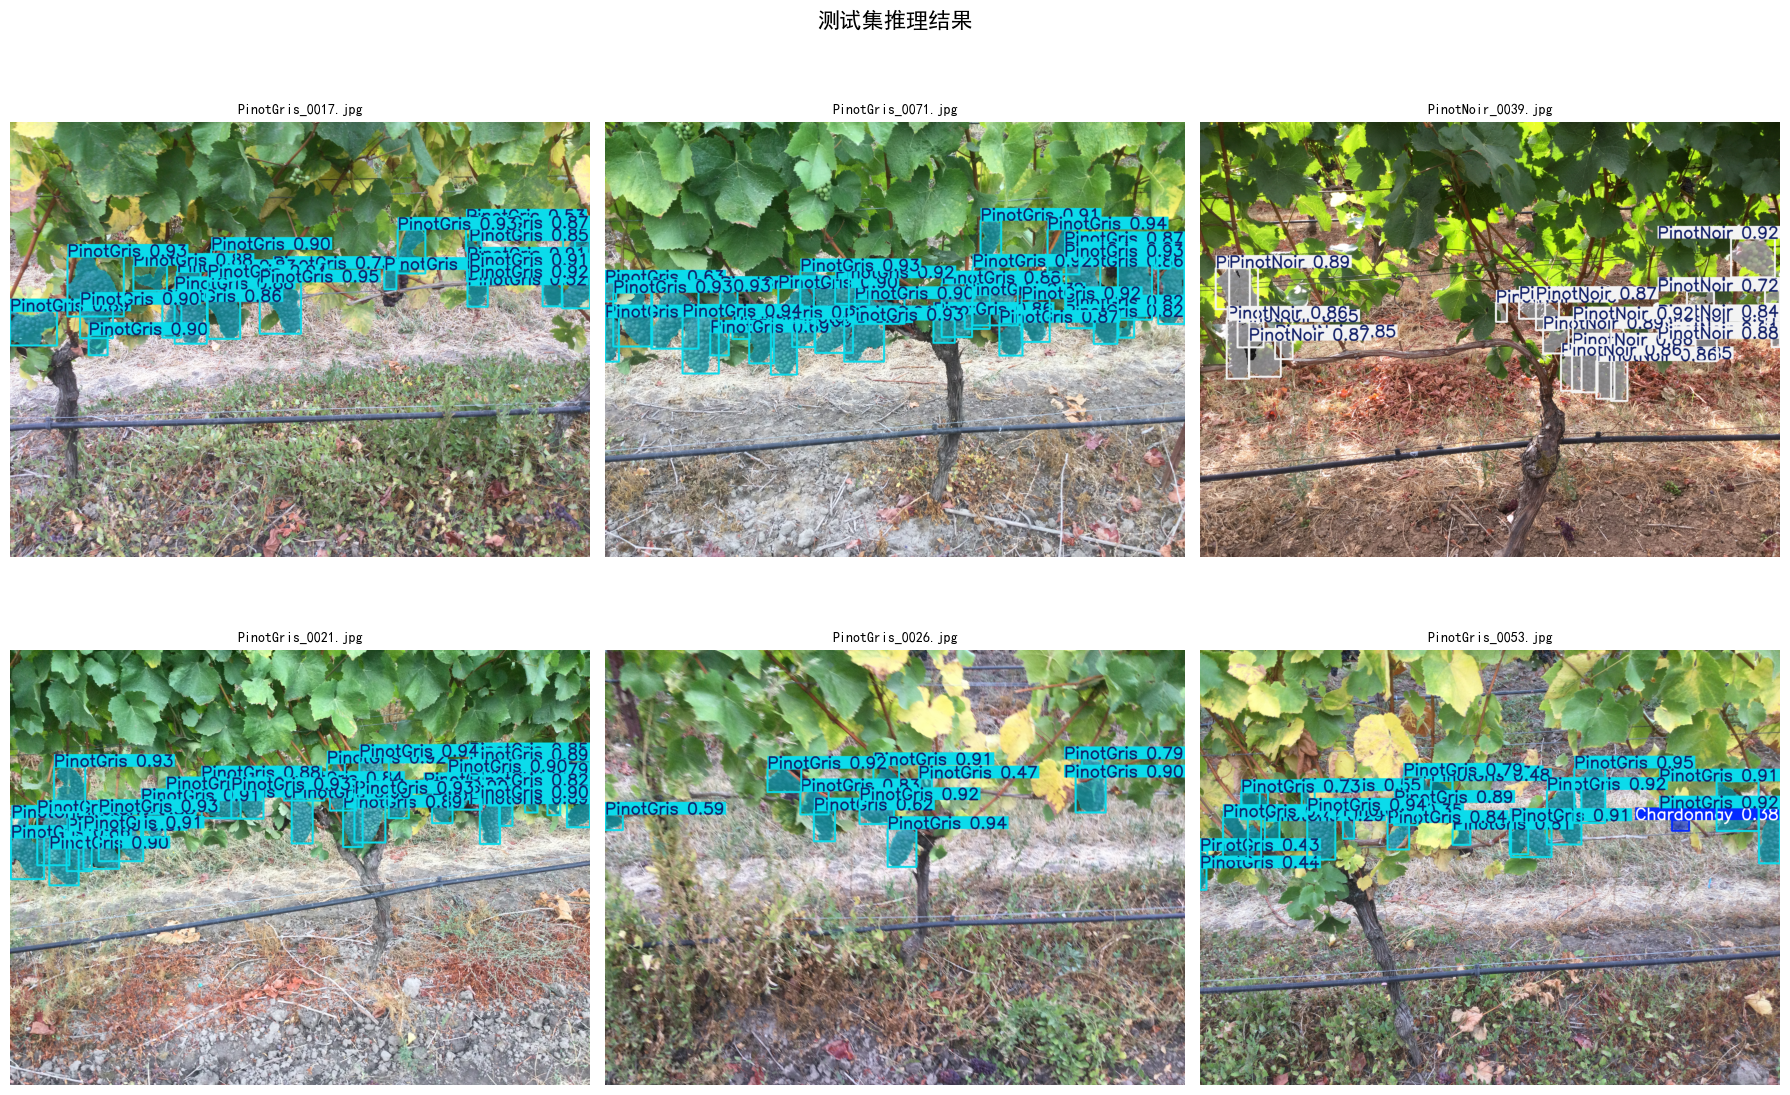

In [12]:
test_images_dir = output_root / 'test' / 'images'
test_files = list(test_images_dir.glob('*.jpg')) + list(test_images_dir.glob('*.JPG'))

if len(test_files) > 0:
    sample_files = np.random.choice(test_files, min(6, len(test_files)), replace=False)
    
    fig = plt.figure(figsize=(18, 12))
    
    for idx, img_file in enumerate(sample_files):
        results = best_model.predict(str(img_file), conf=0.25, verbose=False)
        img_with_results = results[0].plot(boxes=True, labels=True, masks=True)
        img_rgb = cv2.cvtColor(img_with_results, cv2.COLOR_BGR2RGB)
        
        ax = fig.add_subplot(2, 3, idx + 1)
        ax.imshow(img_rgb)
        ax.set_title(img_file.name, fontsize=10)
        ax.axis('off')
    
    plt.suptitle('测试集推理结果', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('测试集为空')

## 13. 训练总结

In [13]:
print('='*70)
print('训练完成总结')
print('='*70)
print(f'SAM模型: {CONFIG["sam_model_type"]}')
print(f'YOLO模型: {CONFIG["model_size"]}')
print(f'训练样本: {len(train_samples)}')
print(f'验证样本: {len(val_samples)}')
print(f'测试样本: {len(test_samples)}')
print(f'\n性能指标:')
print(f'  Box mAP@0.5: {metrics.box.map50:.4f}')
print(f'  Mask mAP@0.5: {metrics.seg.map50:.4f}')
print(f'\n模型文件: {final_model_path}')
print(f'类别: {CONFIG["varieties"]}')
print('='*70)
print('\n✓ 训练完成！模型已准备好用于前端应用')
print(f'  app_grape_segment.py 会自动加载: {final_model_path}')

训练完成总结
SAM模型: vit_b
YOLO模型: yolov8m-seg.pt
训练样本: 348
验证样本: 74
测试样本: 76

性能指标:
  Box mAP@0.5: 0.9637
  Mask mAP@0.5: 0.9470

模型文件: D:\WorkSpace2\plants-intelligent-system\models\grape_segment_model.pt
类别: ['Chardonnay', 'PinotGris', 'PinotNoir']

✓ 训练完成！模型已准备好用于前端应用
  app_grape_segment.py 会自动加载: D:\WorkSpace2\plants-intelligent-system\models\grape_segment_model.pt
